In [1]:
!nvidia-smi

Thu Oct  8 23:53:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import os
HOME = os.getcwd()
print(HOME)

/kaggle/working


In [3]:
# Pip install method (recommended)

!pip install ultralytics 

from IPython import display
display.clear_output()

import ultralytics
ultralytics.checks()

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7087.0/8156.9 GB disk)


In [4]:
from ultralytics import YOLO

from IPython.display import display, Image

In [10]:
from kaggle_secrets import UserSecretsClient
from roboflow import Roboflow

user_secrets = UserSecretsClient()
api_key = user_secrets.get_secret("ROBOFLOW_API_KEY")

rf = Roboflow(api_key=api_key)

project = rf.workspace("mel-cabral-fiore-brito").project("libras-unificado")
version = project.version(1)
dataset = version.download("yolov8")

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to libras-unificado-1 in yolov8:: 100%|██████████| 21450/21450 [00:01<00:00, 11426.35it/s]


In [14]:
!ls /kaggle/working/libras-unificado-1/test


images	labels


Modify data.yaml with the correct path:

test: /kaggle/working/libras-unificado-1/test/images

train: /kaggle/working/libras-unificado-1/train/images

val: /kaggle/working/libras-unificado-1/valid/images


In [15]:
MODEL = 'yolov8n.pt'
IMG_SIZE = 640
EPOCHS = 70
HALF=True

In [16]:
%cd {HOME}
!yolo task=detect mode=train model={MODEL} data={dataset.location}/data.yaml epochs={EPOCHS} imgsz={IMG_SIZE} plots=True fliplr=0.0 

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/libras-unificado-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.4, exist_ok=False, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opse

In [17]:
import glob

last_run = sorted(glob.glob(f'{HOME}/runs/detect/train*'))[-1]
print(f"Usando a pasta: {last_run}")

Usando a pasta: /kaggle/working/runs/detect/train


In [18]:
!ls {last_run}

args.yaml			 results.csv	       val_batch0_labels.jpg
BoxF1_curve.png			 results.png	       val_batch0_pred.jpg
BoxP_curve.png			 train_batch0.jpg      val_batch1_labels.jpg
BoxPR_curve.png			 train_batch1.jpg      val_batch1_pred.jpg
BoxR_curve.png			 train_batch2.jpg      val_batch2_labels.jpg
confusion_matrix_normalized.png  train_batch35220.jpg  val_batch2_pred.jpg
confusion_matrix.png		 train_batch35221.jpg  weights
labels.jpg			 train_batch35222.jpg


In [19]:
   %cd {HOME}
   !yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml agnostic_nms=True plots=True

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,938 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1107.8±292.9 MB/s, size: 28.1 KB)
val: Scanning /kaggle/working/libras-unificado-1/valid/labels.cache... 894 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 894/894 163.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 7.1it/s 7.8s0.1s
                   all        894        894      0.979      0.979      0.973      0.731
                     A         64         64          1      0.988      0.995      0.743
                     B         60         60      0.995          1      0.995      0.774
                     C         74         74       0.97      0.986      0.981      0.629
                     D        104        104      0.969      0.981      0.965      0.681
         

/kaggle/working


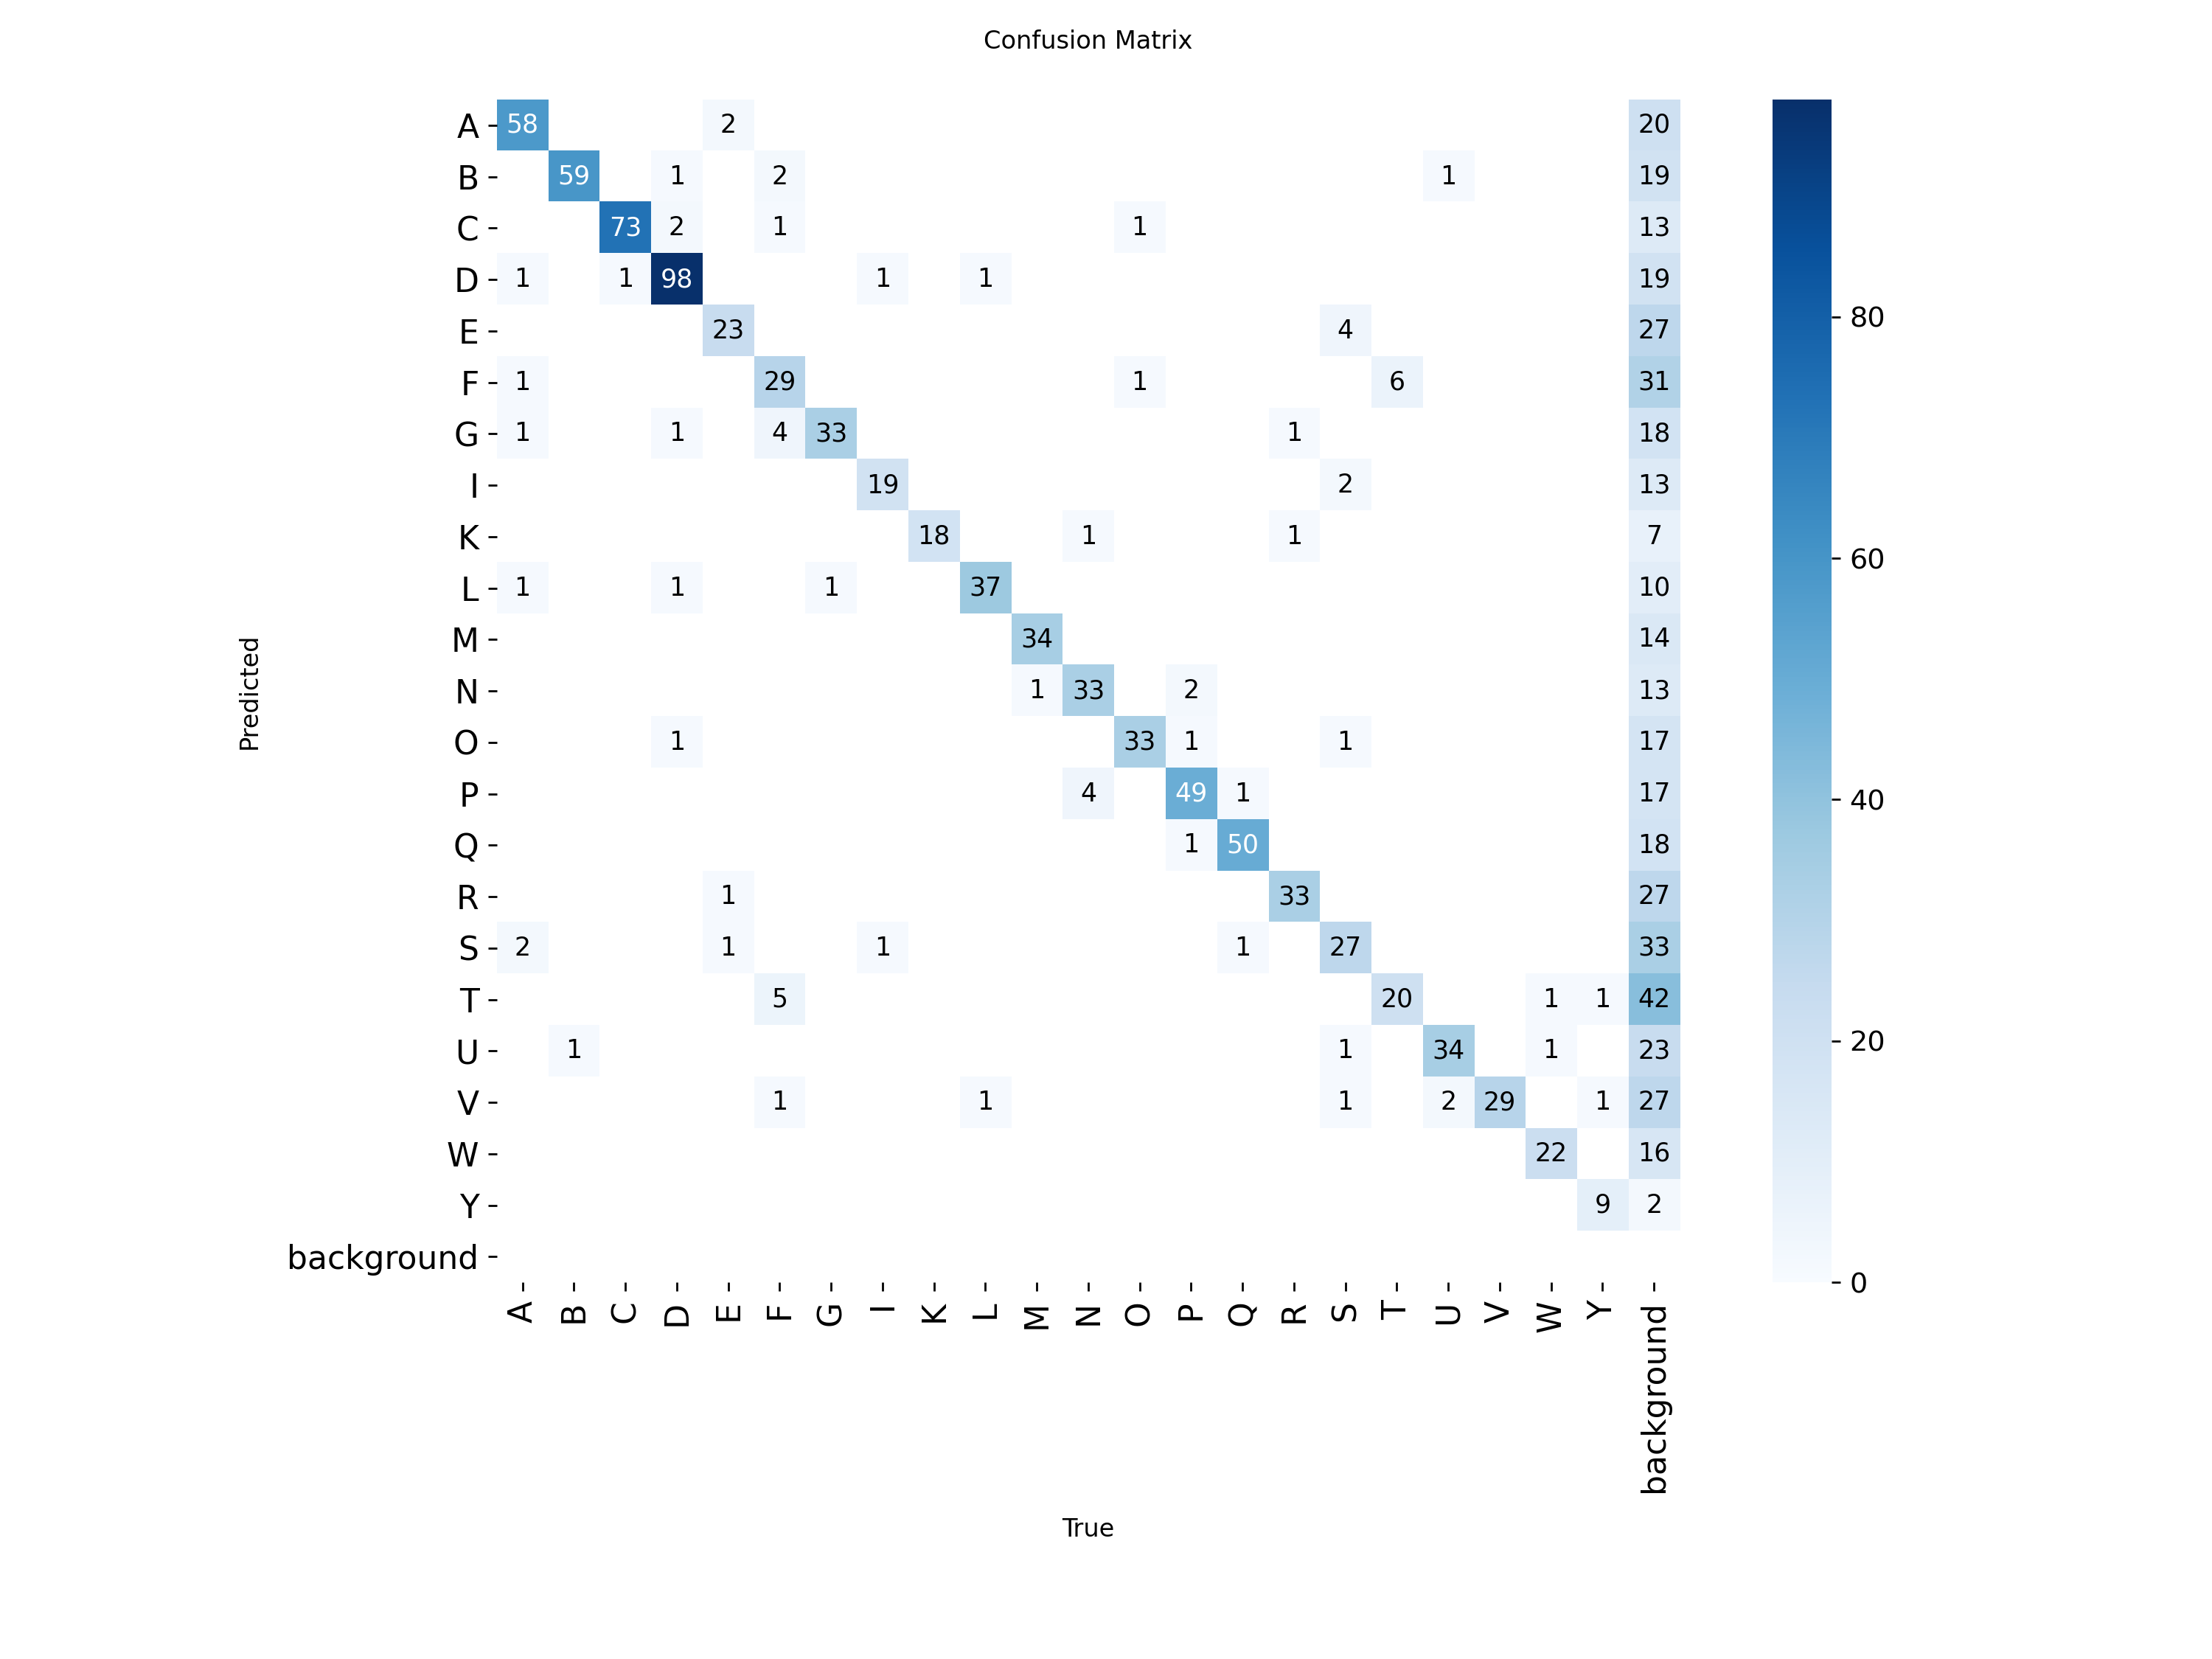

In [20]:
%cd {HOME}
Image(filename=f'{last_run}/confusion_matrix.png', width=600)

In [21]:
%cd {HOME}
!yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml conf=0.25 plots=True
!ls {HOME}/runs/detect

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,938 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1020.2±254.7 MB/s, size: 24.8 KB)
val: Scanning /kaggle/working/libras-unificado-1/valid/labels.cache... 894 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 894/894 163.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 7.1it/s 7.9s0.1s
                   all        894        894      0.981       0.98      0.973      0.731
                     A         64         64      0.984      0.987      0.995      0.742
                     B         60         60          1          1      0.995      0.774
                     C         74         74      0.973      0.986      0.981      0.629
                     D        104        104      0.971      0.981      0.965      0.681
         

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,938 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1108.4±382.3 MB/s, size: 33.7 KB)
val: Scanning /kaggle/working/libras-unificado-1/valid/labels.cache... 894 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 894/894 144.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 7.2it/s 7.8s0.1s
                   all        894        894      0.981       0.98      0.973      0.731
                     A         64         64      0.984      0.987      0.995      0.742
                     B         60         60          1          1      0.995      0.774
                     C         74         74      0.973      0.986      0.981      0.629
                     D        104        104      0.971      0.981      0.965      0.681
         

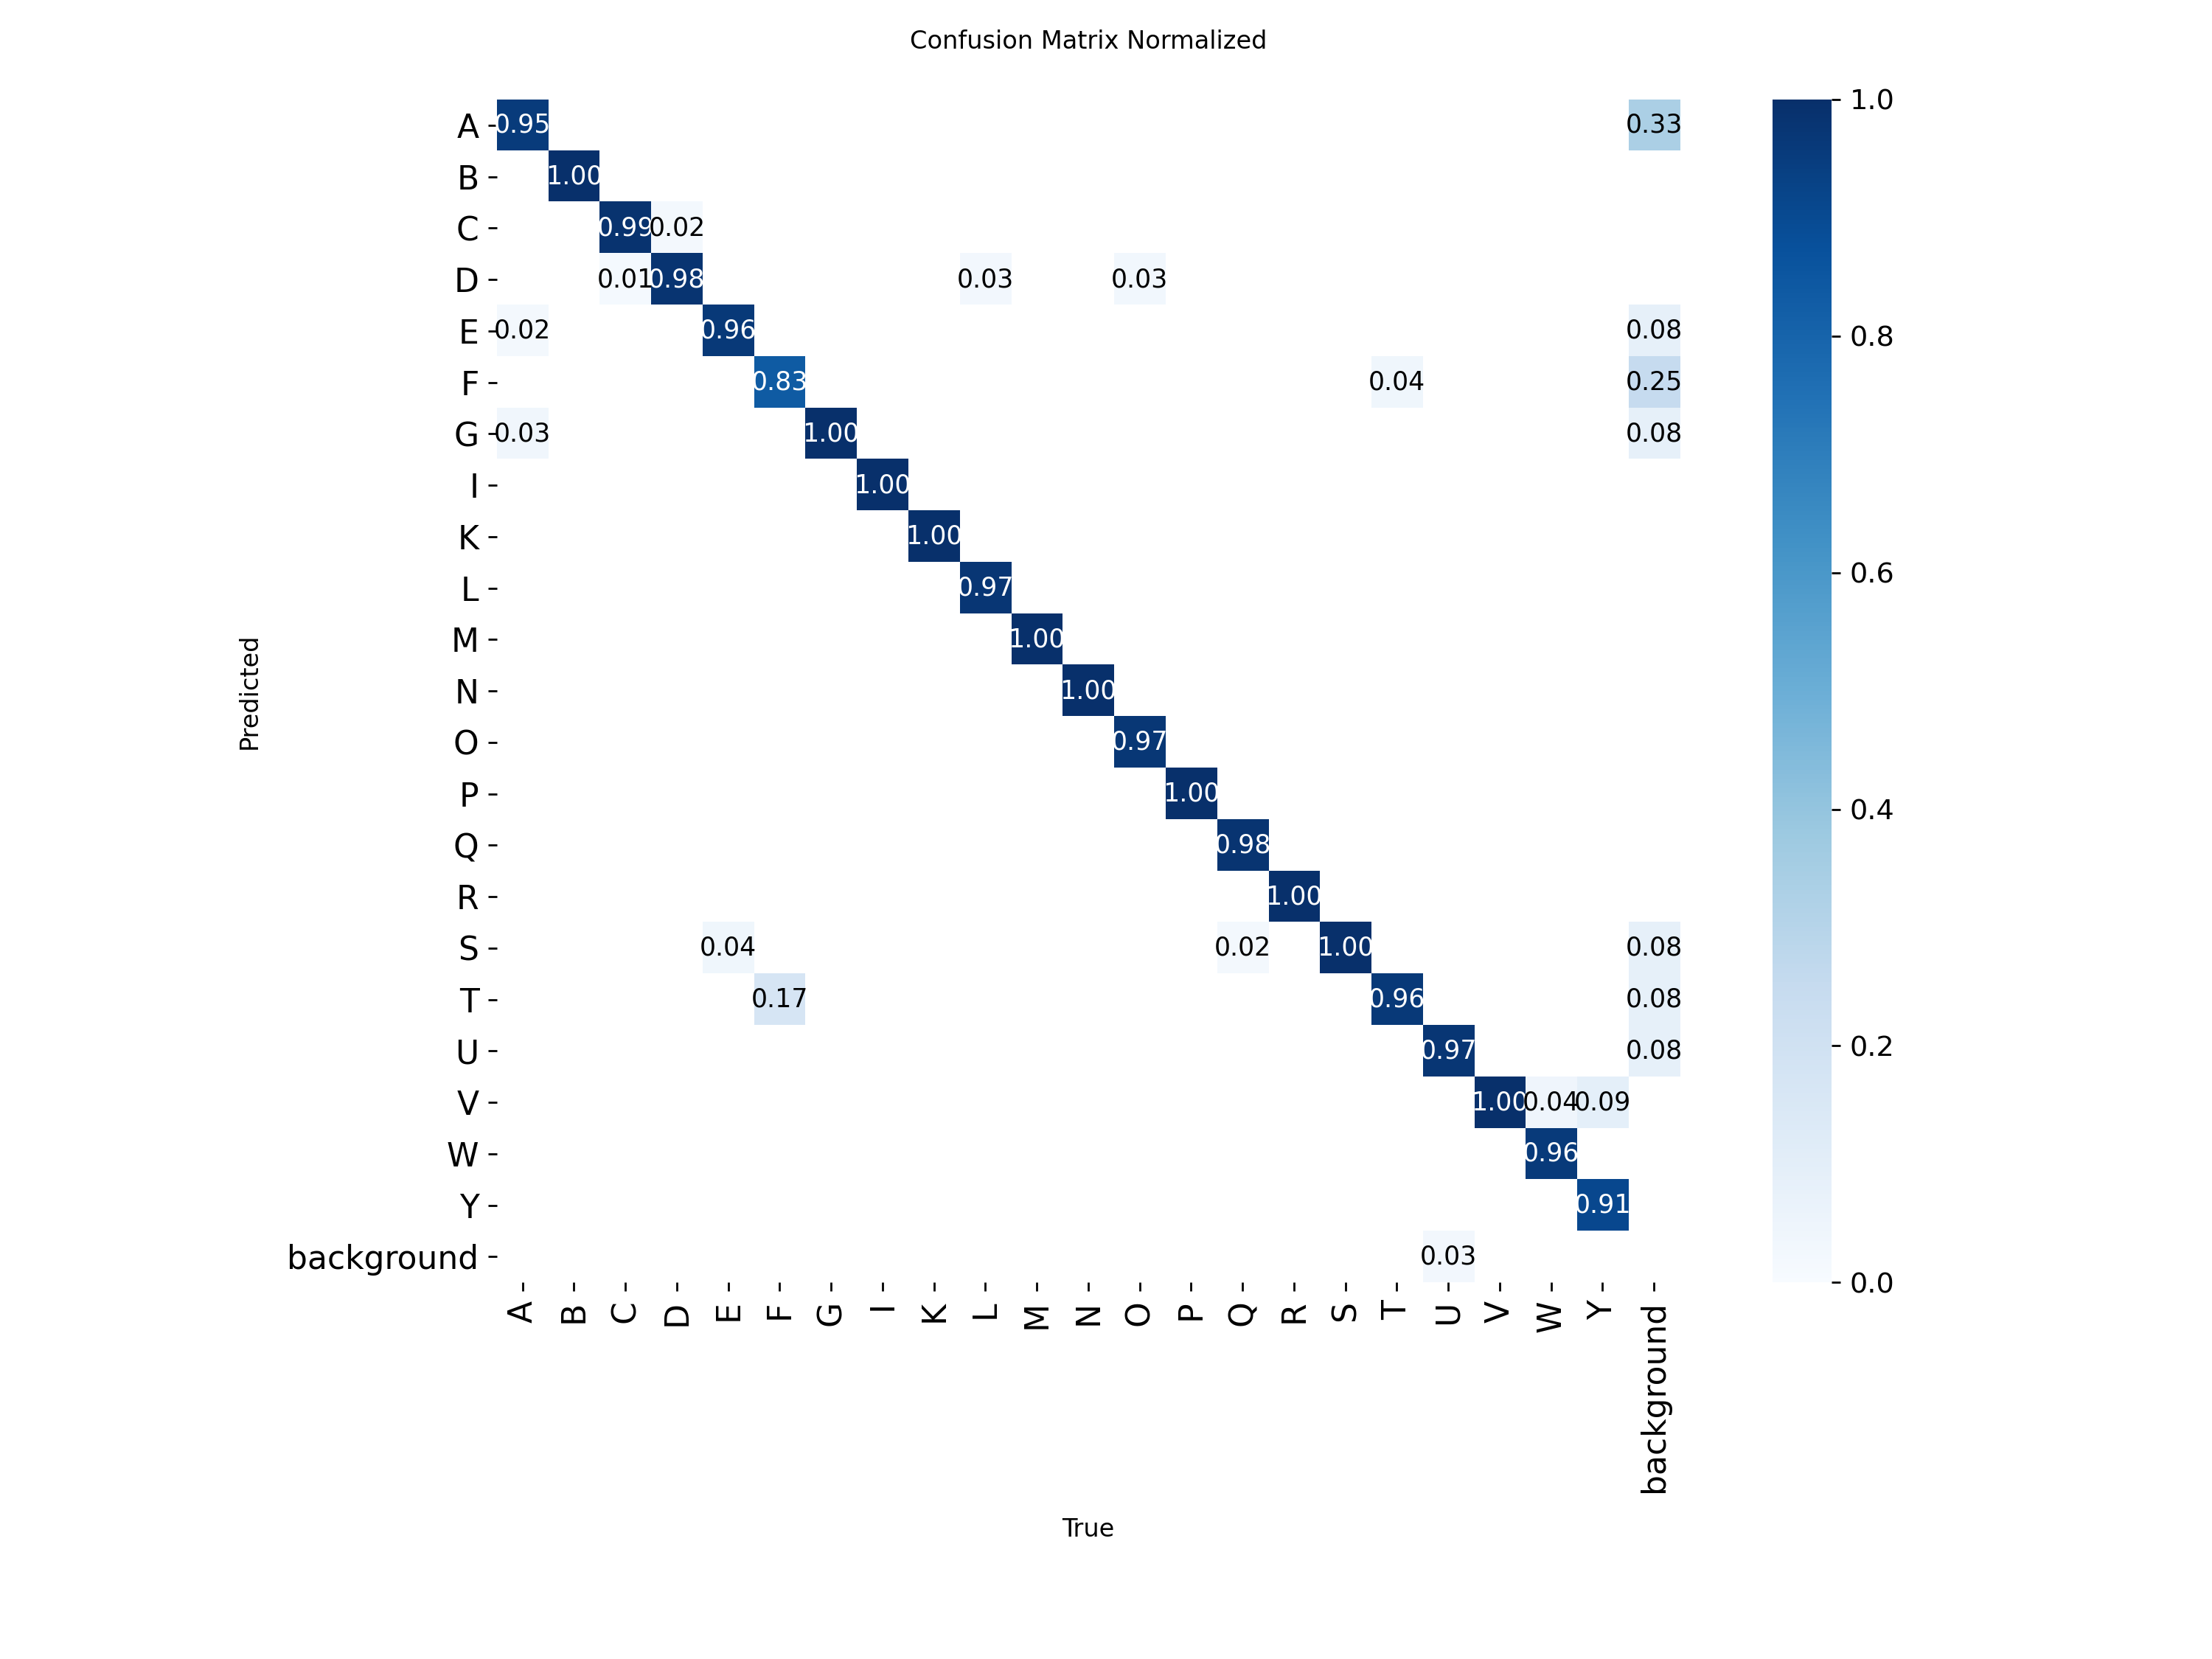

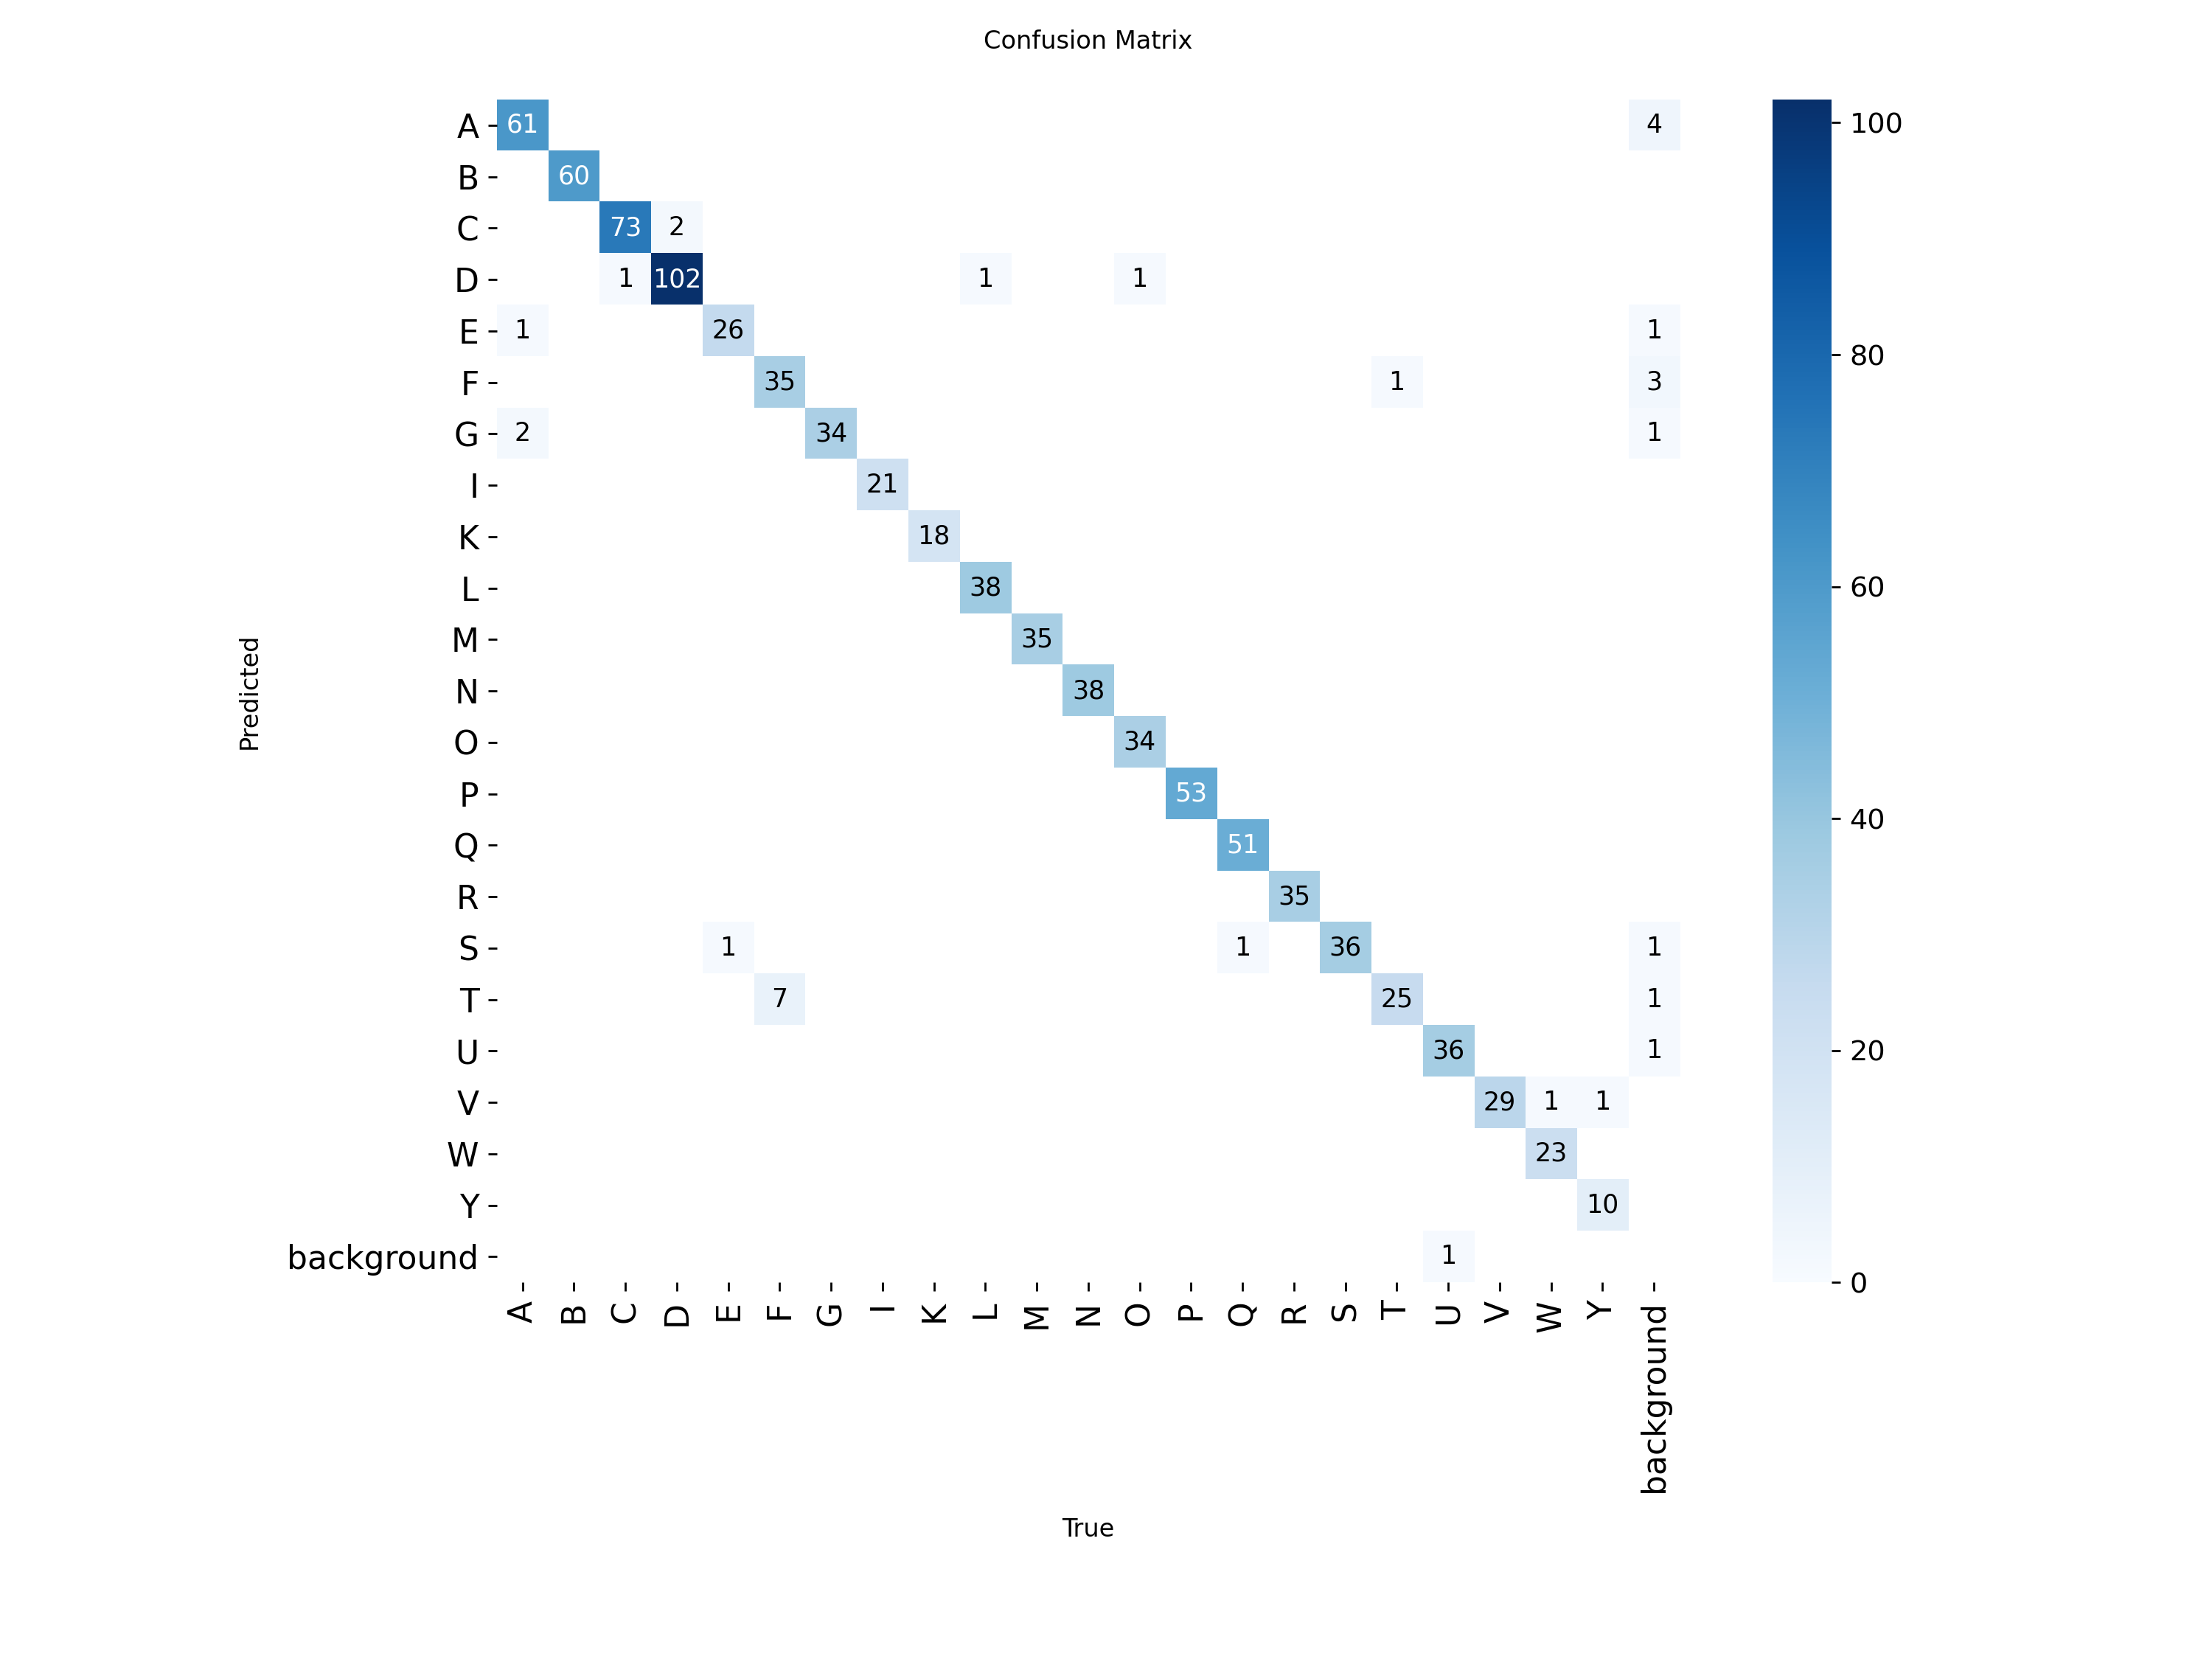

In [22]:
%cd {HOME}
!yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml conf=0.25 plots=True name=val_conf025 exist_ok=True

from IPython.display import Image, display

display(Image(filename=f'{HOME}/runs/detect/val_conf025/confusion_matrix_normalized.png', width=700))
display(Image(filename=f'{HOME}/runs/detect/val_conf025/confusion_matrix.png', width=700))

/kaggle/working


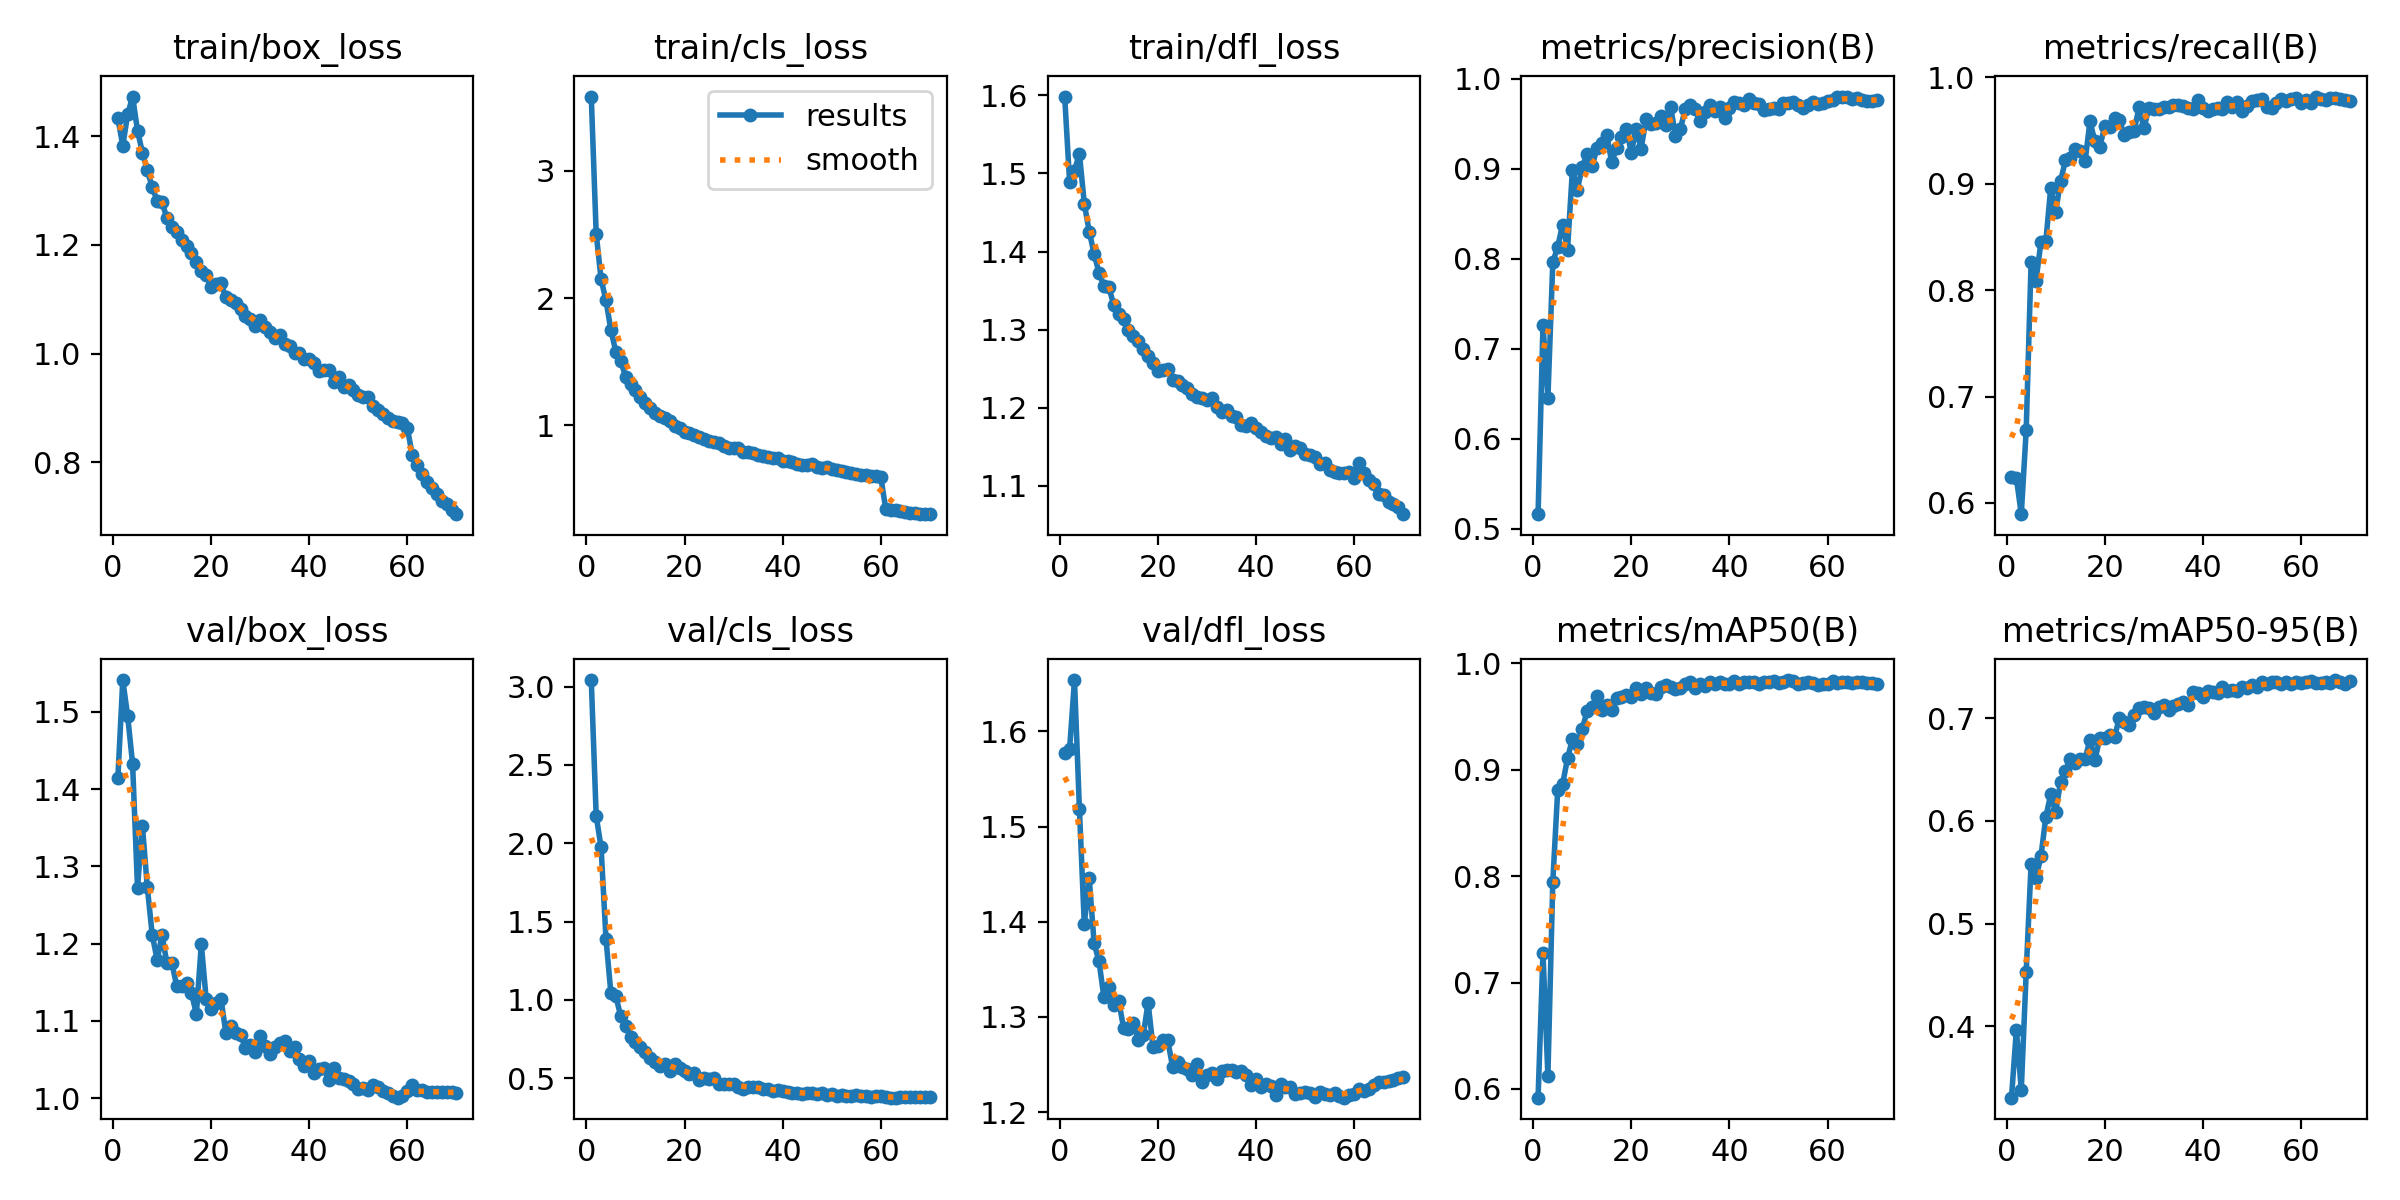

In [23]:
%cd {HOME}
Image(filename=f'{last_run}/results.png', width=600)

/kaggle/working


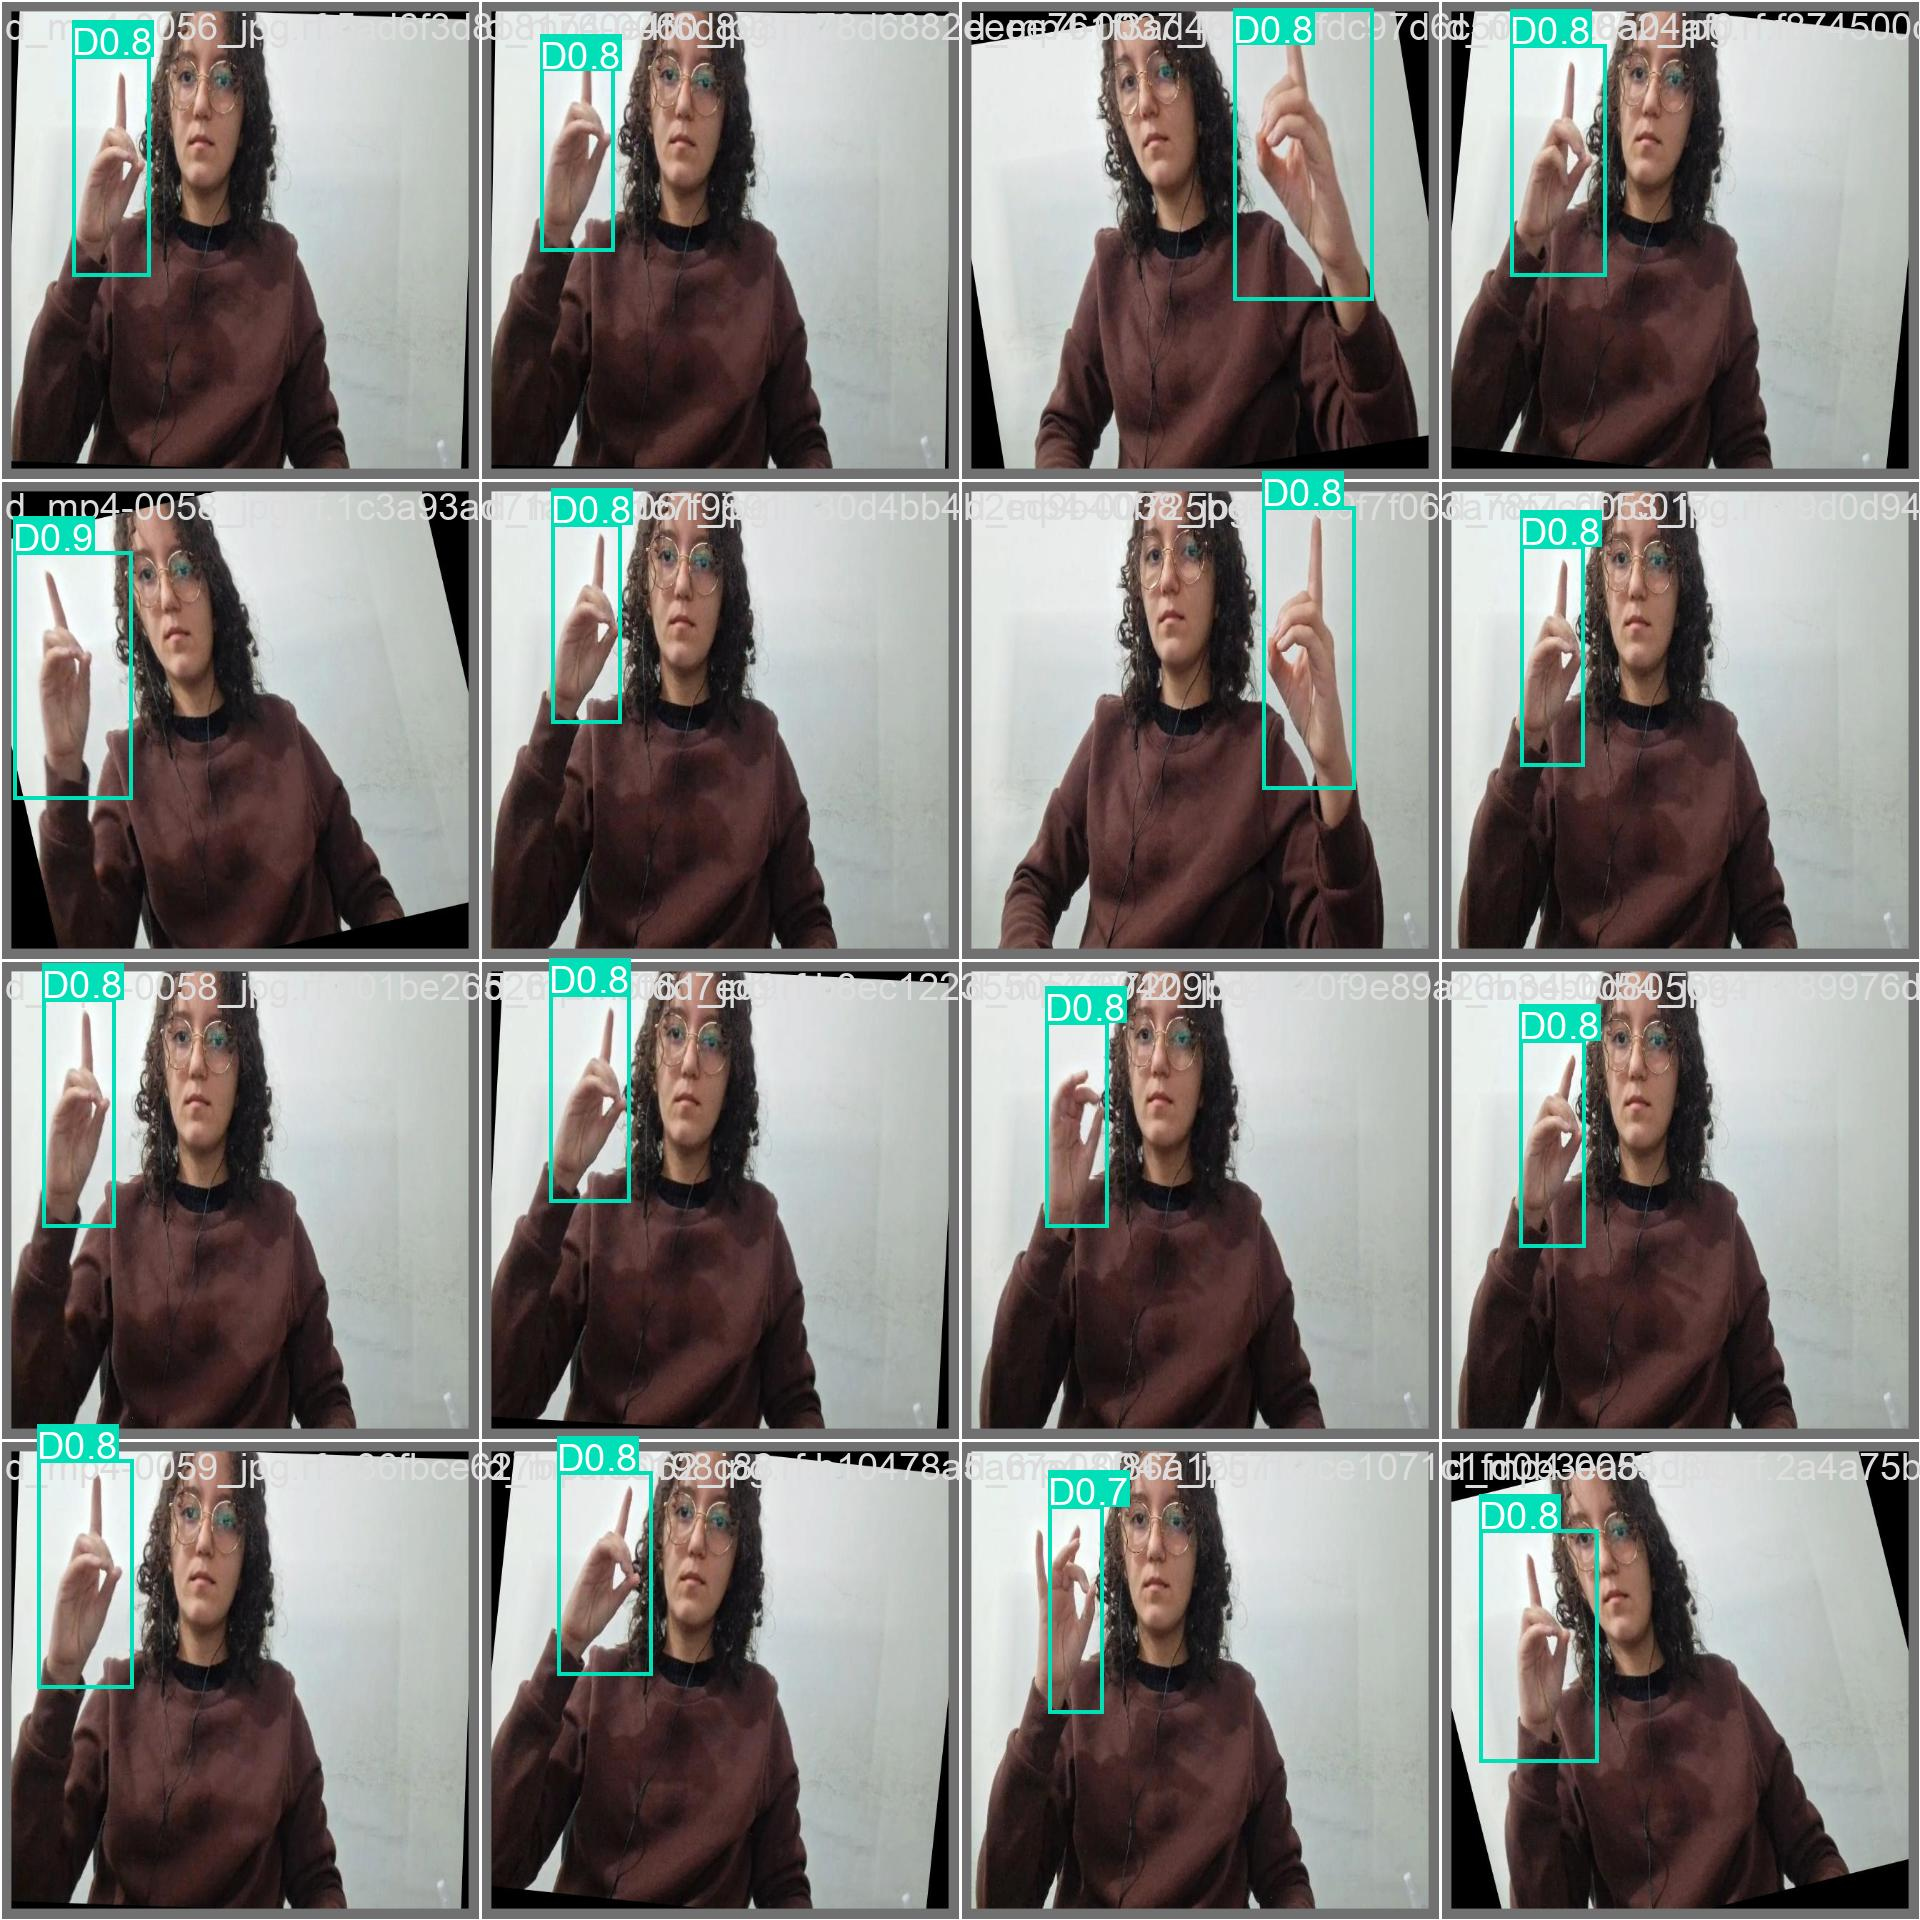

In [24]:
%cd {HOME}
Image(filename=f'{last_run}/val_batch0_pred.jpg', width=600)

In [25]:
%cd {HOME}

!yolo task=detect mode=val model={last_run}/weights/best.pt data={dataset.location}/data.yaml

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,938 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1053.1±134.2 MB/s, size: 28.0 KB)
val: Scanning /kaggle/working/libras-unificado-1/valid/labels.cache... 894 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 894/894 178.6Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 56/56 7.1it/s 7.9s0.1s
                   all        894        894      0.976       0.98      0.982      0.738
                     A         64         64      0.984      0.986      0.995      0.742
                     B         60         60      0.994          1      0.995      0.774
                     C         74         74       0.97      0.986      0.981      0.629
                     D        104        104      0.969      0.981      0.974      0.688
         

In [27]:
%cd {HOME}
!yolo task=detect mode=predict model={HOME}/runs/detect/train/weights/best.pt conf=0.5 source={dataset.location}/test/images save=True name=pred_final exist_ok=True

/kaggle/working
Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,009,938 parameters, 0 gradients, 8.1 GFLOPs

image 1/445 /kaggle/working/libras-unificado-1/test/images/20230807_153919-0-_jpg.rf.d8bf313ec6b2fd9d9aeb44744adf51bf.jpg: 640x640 1 A, 7.4ms
image 2/445 /kaggle/working/libras-unificado-1/test/images/20230807_153934_jpg.rf.693a045fca0d654dfd179a5dcd71e26f.jpg: 640x640 1 A, 8.1ms
image 3/445 /kaggle/working/libras-unificado-1/test/images/20230807_154025_jpg.rf.ef7824969ade14892c4e5ad67602a1f7.jpg: 640x640 1 C, 7.3ms
image 4/445 /kaggle/working/libras-unificado-1/test/images/20230807_154049_jpg.rf.7350cc4048f6287ad3ac572fb50f2fe5.jpg: 640x640 1 C, 7.6ms
image 5/445 /kaggle/working/libras-unificado-1/test/images/20230807_154113-0-_jpg.rf.27991557886bacc6cb671c992e4bba7a.jpg: 640x640 1 D, 7.8ms
image 6/445 /kaggle/working/libras-unificado-1/test/images/20230807_154119_jpg.rf.bec295e43adc3271ffc943ecafe08285.jpg

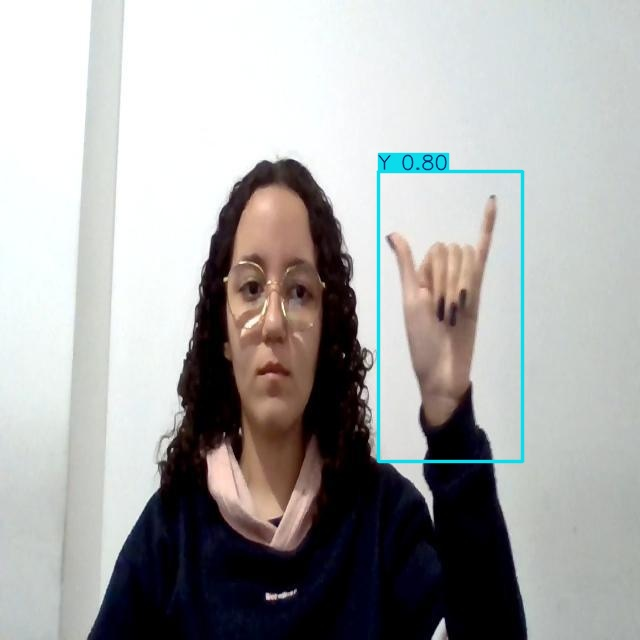

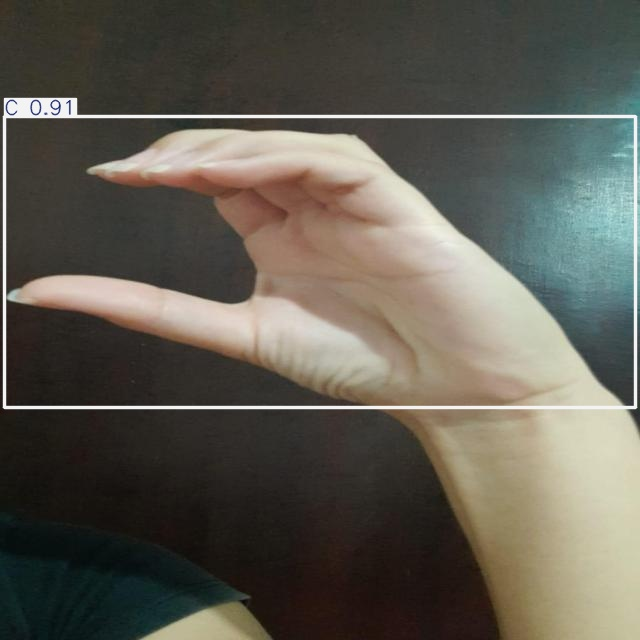

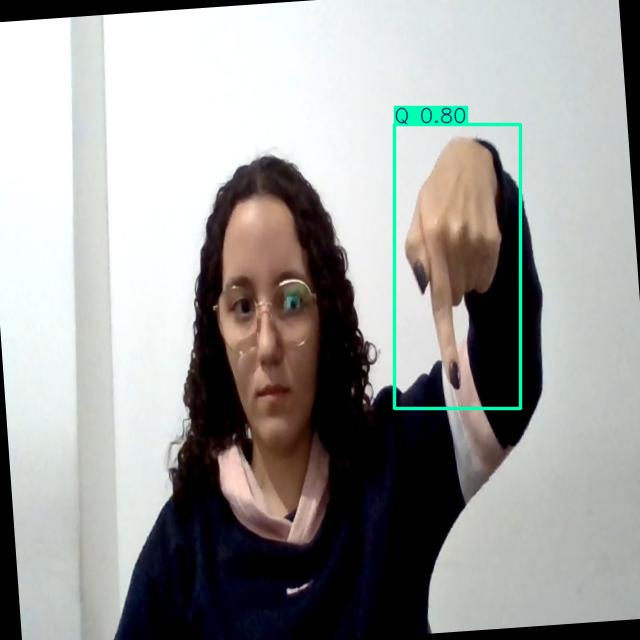

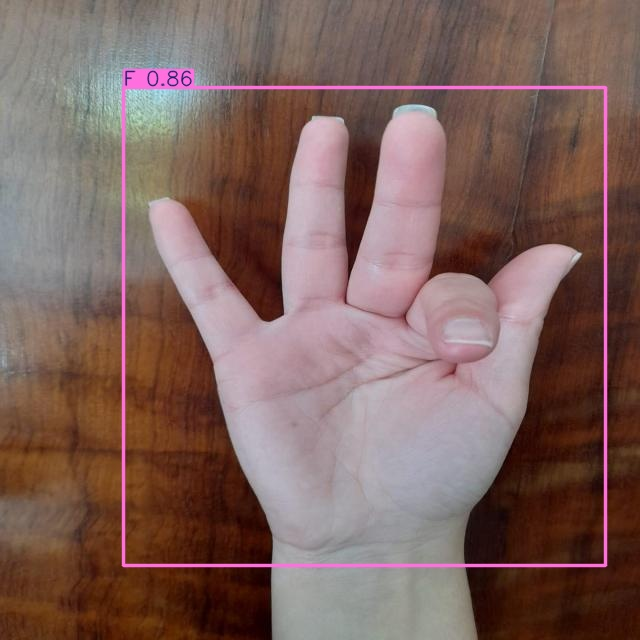

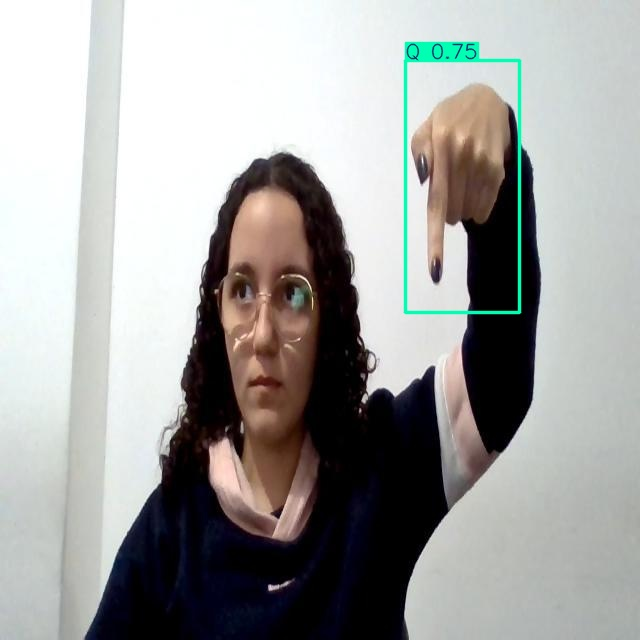

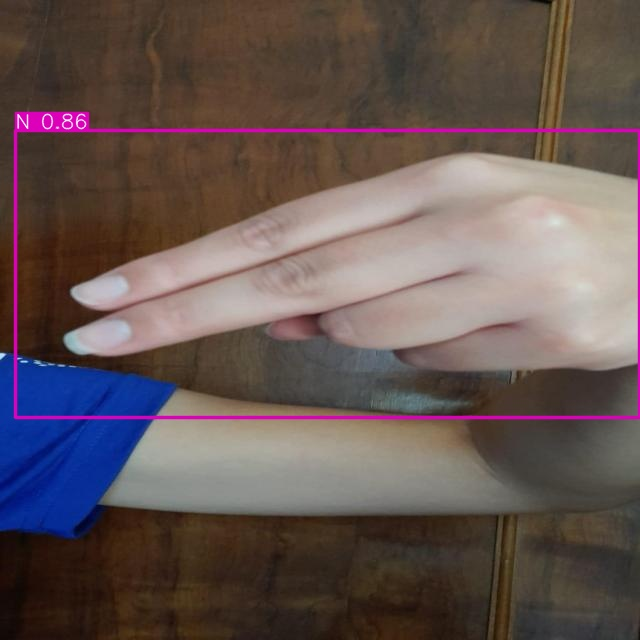

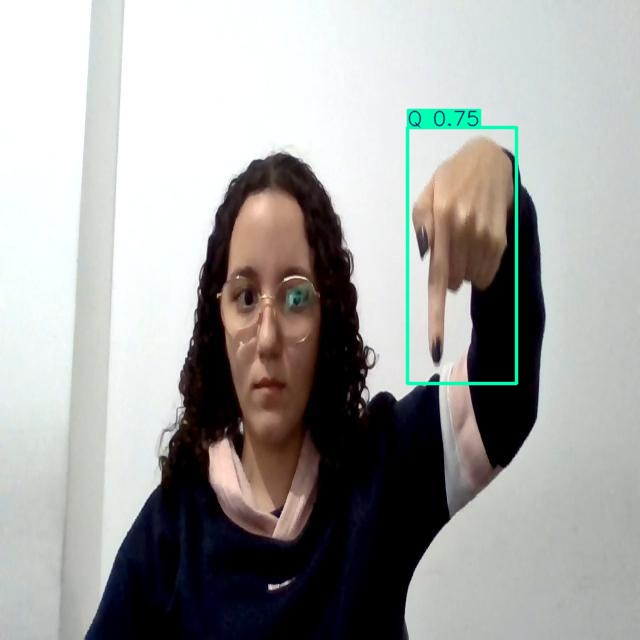

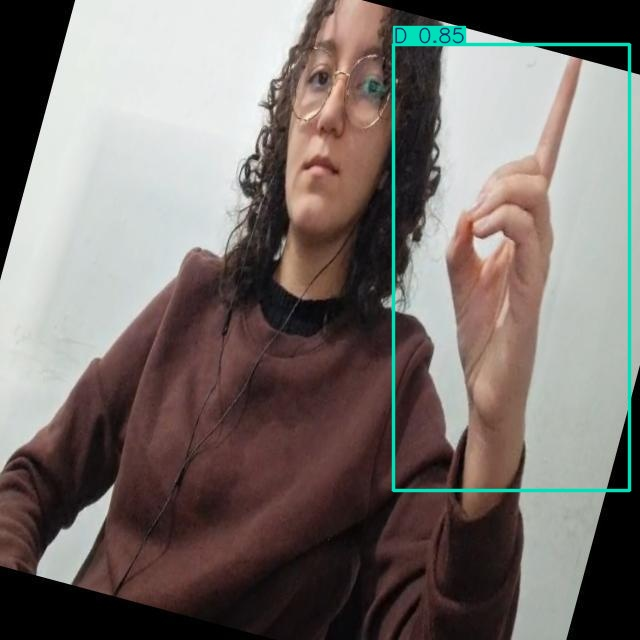

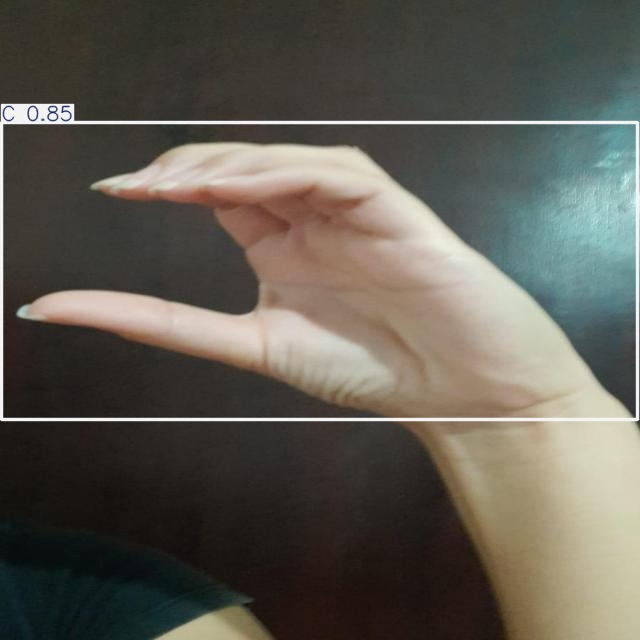

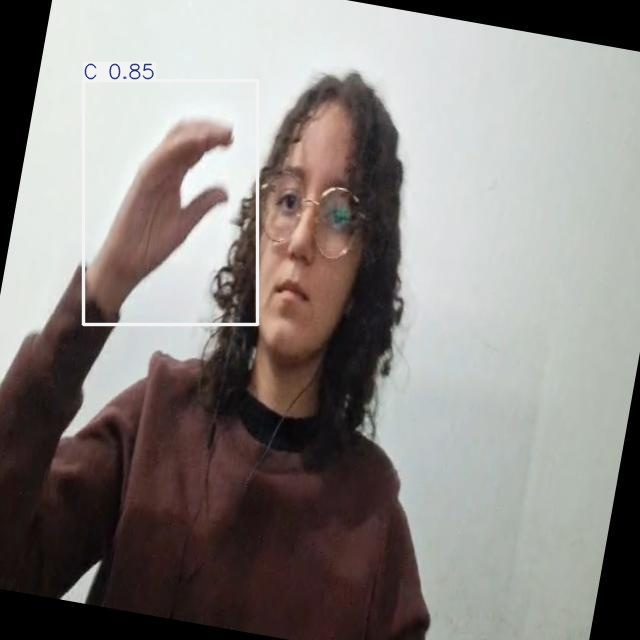

In [28]:
import glob
from IPython.display import Image, display

for image_path in glob.glob(f'{HOME}/runs/detect/pred_final/*.jpg')[:10]:
      display(Image(filename=image_path, width=600))
      print("\n")

In [31]:
import os, shutil, glob

WORKING_DIR = '/kaggle/working'
OUT = f'{WORKING_DIR}/entrega'


for d in ['treino', 'matriz_conf025', 'exemplos']:
    os.makedirs(f'{OUT}/{d}', exist_ok=True)

def copiar(src, dst):
    if os.path.exists(src):
        shutil.copy(src, dst)
        print(f'Copiado: {os.path.basename(src)} -> {dst}')
    else:
        print(f'NÃO ENCONTRADO: {src}')


train_runs = sorted(glob.glob('**/runs/detect/train*', recursive=True), key=os.path.getmtime)
last_run = train_runs[-1] if train_runs else '/kaggle/working/runs/detect/train2'
print(f'-> Pasta de treino detetada: {last_run}\n')


copiar(f'{last_run}/weights/best.pt', OUT)


yaml_files = glob.glob('**/data.yaml', recursive=True)
if yaml_files:
    data_yaml_path = yaml_files[0]
    copiar(data_yaml_path, OUT)             
    copiar(data_yaml_path, f'{OUT}/treino')  
else:
    print('NÃO ENCONTRADO: data.yaml')


metrics = [
    'results.png', 'results.csv', 'args.yaml', 'labels.jpg',
    'val_batch0_labels.jpg', 'val_batch0_pred.jpg',
    'BoxPR_curve.png', 'BoxF1_curve.png', 'BoxP_curve.png', 'BoxR_curve.png',
    'confusion_matrix.png', 'confusion_matrix_normalized.png'
]
for f in metrics:
    copiar(f'{last_run}/{f}', f'{OUT}/treino')


val_conf_runs = sorted(glob.glob('**/runs/detect/val_conf025*', recursive=True), key=os.path.getmtime)
val_dir = val_conf_runs[-1] if val_conf_runs else last_run

for f in ['confusion_matrix.png', 'confusion_matrix_normalized.png']:
    copiar(f'{val_dir}/{f}', f'{OUT}/matriz_conf025')


pred_runs = sorted(glob.glob('**/runs/detect/pred_final*', recursive=True), key=os.path.getmtime)
pred_dir = pred_runs[-1] if pred_runs else last_run

files = sorted(glob.glob(f'{pred_dir}/*.jpg'))
if files:
    step = max(1, len(files) // 20)
    for p in files[::step][:20]:
        shutil.copy(p, f'{OUT}/exemplos')
    print(f'{min(20, len(files))} imagens de exemplo copiadas.')


shutil.make_archive(f'{WORKING_DIR}/entrega', 'zip', OUT)
zip_size = round(os.path.getsize(f'{WORKING_DIR}/entrega.zip') / 1e6, 1)

print(f'\n✅ Entrega gerada com sucesso: entrega.zip ({zip_size} MB)')

-> Pasta de treino detetada: runs/detect/train

Copiado: best.pt -> /kaggle/working/entrega
Copiado: data.yaml -> /kaggle/working/entrega
Copiado: data.yaml -> /kaggle/working/entrega/treino
Copiado: results.png -> /kaggle/working/entrega/treino
Copiado: results.csv -> /kaggle/working/entrega/treino
Copiado: args.yaml -> /kaggle/working/entrega/treino
Copiado: labels.jpg -> /kaggle/working/entrega/treino
Copiado: val_batch0_labels.jpg -> /kaggle/working/entrega/treino
Copiado: val_batch0_pred.jpg -> /kaggle/working/entrega/treino
Copiado: BoxPR_curve.png -> /kaggle/working/entrega/treino
Copiado: BoxF1_curve.png -> /kaggle/working/entrega/treino
Copiado: BoxP_curve.png -> /kaggle/working/entrega/treino
Copiado: BoxR_curve.png -> /kaggle/working/entrega/treino
Copiado: confusion_matrix.png -> /kaggle/working/entrega/treino
Copiado: confusion_matrix_normalized.png -> /kaggle/working/entrega/treino
Copiado: confusion_matrix.png -> /kaggle/working/entrega/matriz_conf025
Copiado: confusion_